# 决策树算法：基本指标、模型训练

本节的代码包含三部分：决策树基本计算、手动实现 ID3 算法，以及使用 scikit-learn 构建决策树。基础练习在最后。


## 一. 决策树的基本计算


In [2]:
from math import log  
 
def calc_shannon_ent(data_set):  
    """ 
    计算香农熵 
    :param data_set:数据集 
    :return: 计算结果 
    """  
    num_entries = len(data_set) #保存数据集中实例的总数  
    label_counts = {}  
    #-----------------------  
    # 为所有可能分类创建字典  
    #-----------------------  
    for vec in data_set: # 遍历每个实例，统计标签的频数  
        current_label = vec[-1]  #设样本的最后一列的数值为键值  
        if current_label not in label_counts.keys():  
            label_counts[current_label] = 0  
        label_counts[current_label] += 1  
    shannon_ent = 0.0  
    for key in label_counts:  
        prob = float(label_counts[key]) / num_entries  
        shannon_ent -= prob * log(prob,2) # 以2为底的对数  
    return shannon_ent  

In [3]:
#创建数据集  
def create_data_set():  
    data_set = [[1,1,'y'],  
                [1,1,'y'],  
                [1,0,'n'],  
                [0,0,'n'],  
                [0,1,'n']  
                ]  
    labels = ['gill', 'fin']  
    return data_set, labels  

In [4]:
#使用自定义函数来计算香农熵
my_data,labels = create_data_set()  
print(my_data) 
print(calc_shannon_ent(my_data))  

[[1, 1, 'y'], [1, 1, 'y'], [1, 0, 'n'], [0, 0, 'n'], [0, 1, 'n']]
0.9709505944546686


In [5]:
#如果有更多的分类呢?  
my_data[-1][-1]='not sure'  
print(my_data)  
print(calc_shannon_ent(my_data) )

[[1, 1, 'y'], [1, 1, 'y'], [1, 0, 'n'], [0, 0, 'n'], [0, 1, 'not sure']]
1.5219280948873621


In [6]:
# 划分数据集
def split_data_set(data_set, axis, value):  
    ''''' 
    按照给定特征划分数据集 
    :param data_set:待划分的数据集 
    :param axis:划分数据集所用的特征 
    :param value: 特征的返回值 
    :return: 划分结果列表 
    '''  
    ret_data_set = []   # 为了不修改原始数据,新建一个列表  
    for vec in data_set:  # vec: 样本, 某一行的数据  
        if vec[axis] == value:  
            reduced_vec = vec[:axis]    
            reduced_vec.extend(vec[axis+1:])  
            ret_data_set.append(reduced_vec)  
    return ret_data_set  
  
my_data,labels = create_data_set()  
print(my_data) 
print(split_data_set(my_data,0,0) )
print(split_data_set(my_data,2,"y") )
print(split_data_set(my_data,1,1) )

[[1, 1, 'y'], [1, 1, 'y'], [1, 0, 'n'], [0, 0, 'n'], [0, 1, 'n']]
[[0, 'n'], [1, 'n']]
[[1, 1], [1, 1]]
[[1, 'y'], [1, 'y'], [0, 'n']]


In [7]:
# 选择最好的划分方式
def best_feature_to_split(data_set): # data_set 必须是以长度相同的列表为元素的列表. 每个样本的最后一个元素是当前样本的类别标签  
    num_features = len(data_set[0])-1   # 求出当前数据集包含的特征的数目.  
    base_entropy = calc_shannon_ent(data_set) # 求出原始香农值  
    best_info_gain = 0.0   
    best_feature = -1  
    for i in range(num_features): # 遍历所有特征  
        feat_list = [example[i] for example in data_set] # 将所有第i个特征值或所有可能存在的值写入新列表  
        unique_values = set(feat_list)   # 去除重复元素  
        new_entropy = 0.0   
        for value in unique_values: #遍历所有唯一特征值  
            sub_data_set = split_data_set(data_set,i, value) #对每个特征划分一次数据集  
            prob = len(sub_data_set)/float(len(data_set))  
            new_entropy += prob * calc_shannon_ent(sub_data_set) # 计算数据集的新的香农熵.   
        info_gain = base_entropy - new_entropy  
        if (info_gain > best_info_gain):  
            best_info_gain = info_gain  
            best_feature = i  
    return best_feature  

my_data, labels = create_data_set()  
print("my_data:")  
print(my_data)  
print("best feature:")  
print(best_feature_to_split(my_data))  


my_data:
[[1, 1, 'y'], [1, 1, 'y'], [1, 0, 'n'], [0, 0, 'n'], [0, 1, 'n']]
best feature:
0


In [8]:
#计算数据集中类别标签的个数
from math import pow  
  
def label_uniq_counts(data):  
    """ 
    input: data(list) 
    output: label_uniq_counts(int) 
    """  
    label_uniq_count ={}  
  
    for x in data:  
        label = x[len(x)-1] # 取得每个样本的类标签label  
        if label not in label_uniq_count:  # WHY?  
            label_uniq_count[label] = 0  
        label_uniq_count[label]  += 1  
    return label_uniq_count  

label_uniq_counts(my_data)

# Gini指数
def cal_gini_index(data_set):  
    """计算给定数据集的Gini指数 
    input: data(list): 数据集
    output: gini(float): Gini指数
    """  
    # Total no. of the sample  
    total_sample = len(data_set)  
    if len(data_set)==0:  
        return 0  
    # Count the no. of labels in the data set  
    label_counts = label_uniq_counts(data_set)  
  
    # Calculate the Gini index of the data set  
    gini = 0  
    for label in label_counts:  
        gini = gini + pow(label_counts[label],2)  
  
    gini = 1 - float(gini)/ pow(total_sample,2)  
    return gini

print("Gini index:", cal_gini_index(my_data))


Gini index: 0.48


In [9]:
# 训练决策树 
# 1. 导入模块  
from sklearn.tree import DecisionTreeClassifier  
import numpy as np  
    
#2. 创建自己的数据集  
  
#create dataset  
class Fish:  
    def __init__(self):  
        X = [[1,1],  
             [1,1],  
             [1,0],  
             [0,1],  
             [0,1]  
             ]  
        y = [1,1,0,0,0]  
        self.data = np.array(X)  
        self.label = np.array(y)  
        self.feature = np.array(['鳃','鳍'])     
# 训练集  
fs = Fish()  
  
print('X: ', fs.data)  
print('y:',fs.label)    
  
# 训练集的特征  
X = fs.data  
# 训练集的标签  
y = fs.label  
  
#3.1 分类器这个类之实例化  
tree_clf = DecisionTreeClassifier(max_depth=2)  

# 3.2 最终生成决策树模型  
tree_clf.fit(X,y)  
  
# 传入一个数据集,用决策树做预测  
# predict_proba(测试集): 返回值: 一个ndarray数组,其行数为样本个数,其列数为种类数.  
a = tree_clf.predict_proba([[1,1],[0,0]])  

# predict(测试集): 函数的返回值: 一个一维array数组,其列数为样本个数  
b = tree_clf.predict([[1,0]])  
c = tree_clf.predict([[1,1],[1,0]])  
print('测试样本为各类的概率:',a)  
print('分类预测结果',c)  

X:  [[1 1]
 [1 1]
 [1 0]
 [0 1]
 [0 1]]
y: [1 1 0 0 0]
测试样本为各类的概率: [[0. 1.]
 [1. 0.]]
分类预测结果 [1 0]


## 二. 手动实现ID3算法

**ID3(Iterative Dichotomiser 3)** 是由Ross Quinlan 于 1986 年提出的一种经典决策树分类算法。其核心思想是：利用信息增益（Information Gain）选择最优划分特征，递归构建决策树。

ID3算法步骤为：
1. 计算信息熵：计算当前数据集的熵 $H(D)$。
2. 计算信息增益：分别计算所有候选特征的信息增益。
3. 选择最优特征：选择信息增益最大的特征作为当前节点。
4. 划分数据集：按照该特征的不同取值，将数据分为若干子集。
5. 递归构建：对每个子集重复上述过程，直到样本属于同一类别、没有剩余特征或满足其他停止条件


**例2**：根据天气决定是否打球。假设我们收集了 14 天的天气数据，包含四个特征：
- 天气（Outlook）：晴天、阴天、雨天。
- 温度（Temperature）：热、适中、冷。
- 湿度（Humidity）：高、正常。
- 风（Wind）：弱、强。
目标变量是 PlayTennis，表示是否适合打网球。

步骤如下： 1--6.

### 1. 创建数据集

In [10]:

import pandas as pd

data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
        "Overcast", "Sunny", "Sunny", "Rain", "Sunny",
        "Overcast", "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild", "Cool", "Cool",
        "Cool", "Mild", "Cool", "Mild", "Mild",
        "Mild", "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High", "Normal", "Normal",
        "Normal", "High", "Normal", "Normal", "Normal",
        "High", "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Strong"
    ],
    "PlayTennis": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "Yes", "Yes", "Yes",
        "Yes", "Yes", "No"
    ]
}

df = pd.DataFrame(data)
display(df)


,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


接下来，我们手动实现ID3算法。
### 2. 定义信息熵

In [11]:
#定义信息熵
import numpy as np

def entropy(y):
    probabilities = y.value_counts(normalize=True)
    return -sum(
        p * np.log2(p) for p in probabilities if p > 0
    )

print("Dataset entropy:", entropy(df["PlayTennis"]))


Dataset entropy: 0.9402859586706311


### 3. 定义信息增益

信息增益定义为：
$$
IG(D,A) = H(D) - \sum_{v\in \mathcal{V}(A)}\frac{|D_v|}{|D|} H(D_v).
$$

In [12]:
# 定义信息增益

def information_gain(df, feature, target):
    total_entropy = entropy(df[target])
    conditional_entropy = 0.0

    for value, subset in df.groupby(feature):
        weight = len(subset) / len(df)
        conditional_entropy += weight * entropy(subset[target])

    return total_entropy - conditional_entropy


features = ["Outlook", "Temperature", "Humidity", "Wind"]

for feature in features:
    gain = information_gain(df, feature, "PlayTennis")
    print(f"{feature:12s}: {gain:.4f}")


Outlook     : 0.2467
Temperature : 0.0292
Humidity    : 0.1518
Wind        : 0.0481


### 4. 递归构建ID3决策树

In [13]:

def id3(df, features, target):
    labels = df[target]

    # 所有样本属于同一类别
    if labels.nunique() == 1:
        return labels.iloc[0]

    # 没有剩余特征
    if not features:
        return labels.mode().iloc[0]

    # 选择信息增益最大的特征
    best_feature = max(
        features,
        key=lambda f: information_gain(df, f, target)
    )

    majority_class = labels.mode().iloc[0]

    tree = {
        "feature": best_feature,
        "default": majority_class,
        "branches": {}
    }

    remaining_features = [
        f for f in features if f != best_feature
    ]

    for value, subset in df.groupby(best_feature):
        subtree = id3(
            subset.drop(columns=[best_feature]),
            remaining_features,
            target
        )
        tree["branches"][value] = subtree

    return tree


tree = id3(df, features, "PlayTennis")
tree


{'feature': 'Outlook',
 'default': 'Yes',
 'branches': {'Overcast': 'Yes',
  'Rain': {'feature': 'Wind',
   'default': 'Yes',
   'branches': {'Strong': 'No', 'Weak': 'Yes'}},
  'Sunny': {'feature': 'Humidity',
   'default': 'No',
   'branches': {'High': 'No', 'Normal': 'Yes'}}}}

In [14]:
# 打印决策树结构
def print_tree(tree, indent=""):
    if not isinstance(tree, dict):
        print(indent + "Predict:", tree)
        return

    feature = tree["feature"]
    for value, subtree in tree["branches"].items():
        print(indent + f"{feature} = {value}")
        print_tree(subtree, indent + "    ")


print_tree(tree)


Outlook = Overcast
    Predict: Yes
Outlook = Rain
    Wind = Strong
        Predict: No
    Wind = Weak
        Predict: Yes
Outlook = Sunny
    Humidity = High
        Predict: No
    Humidity = Normal
        Predict: Yes


### 5. 使用决策树预测新样本


In [15]:

def predict_id3(tree, sample):
    if not isinstance(tree, dict):
        return tree

    feature = tree["feature"]
    value = sample[feature]

    subtree = tree["branches"].get(value)

    if subtree is None:
        return tree["default"]

    return predict_id3(subtree, sample)


new_sample = {
    "Outlook": "Sunny",
    "Temperature": "Cool",
    "Humidity": "High",
    "Wind": "Weak"
}

prediction = predict_id3(tree, new_sample)
print("Prediction:", prediction)


Prediction: No


## 三. 使用scikit-learn构建决策树
如果希望在实际机器学习项目中快速训练决策树，可以使用scikit-learn。
它的"criterion=entropy" 会采用信息增益划分节点，但生成的是二叉树，而不是ID3的多叉树。 

Training accuracy: 1.0


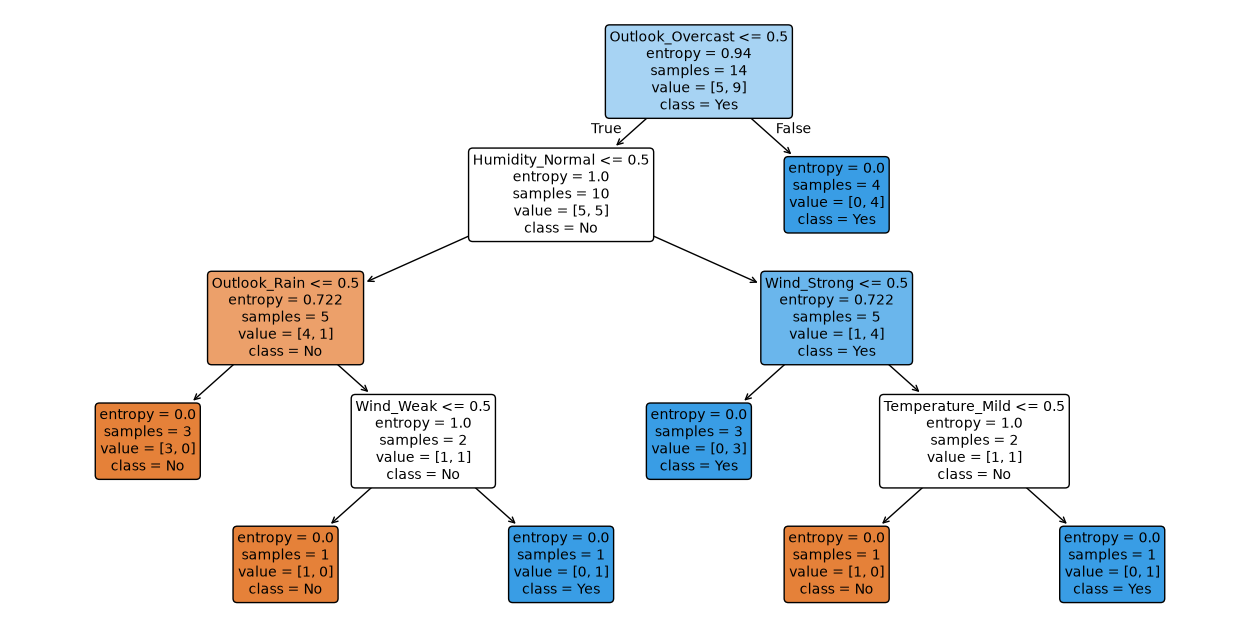

In [16]:

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

# 将类别特征转换为独热编码
# 原本的Outlook经过如下独热编码，会变为三个二元特征
X = pd.get_dummies(df.drop(columns="PlayTennis"))
y = df["PlayTennis"]

# 创建决策树分类器。这里和下面的训练模型构成了核心代码。
# 这里使用信息熵衡量节点的纯度，通过最大化信息增益选择划分。
# 固定随机种子，这样结果就是可重复的。

model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=2
)

# 训练模型：根据训练数据生成决策树。
model.fit(X, y)

# 在训练集上预测
y_pred = model.predict(X)

print("Training accuracy:", accuracy_score(y, y_pred))

# 可视化决策树
plt.figure(figsize=(16, 8))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()


这个例子是在训练数据上评估准确率，只能检查模型是否拟合了已有样本，不能用于判断模型对新数据的泛化能力。实际应用中需要另外划分训练集和测试集，或使用交叉验证。

In [17]:
# 也可以以文本形式查看决策树
from sklearn.tree import export_text

tree_rules = export_text(
    model,
    feature_names=list(X.columns)
)

print(tree_rules)


|--- Outlook_Overcast <= 0.50
|   |--- Humidity_Normal <= 0.50
|   |   |--- Outlook_Rain <= 0.50
|   |   |   |--- class: No
|   |   |--- Outlook_Rain >  0.50
|   |   |   |--- Wind_Weak <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Wind_Weak >  0.50
|   |   |   |   |--- class: Yes
|   |--- Humidity_Normal >  0.50
|   |   |--- Wind_Strong <= 0.50
|   |   |   |--- class: Yes
|   |   |--- Wind_Strong >  0.50
|   |   |   |--- Temperature_Mild <= 0.50
|   |   |   |   |--- class: No
|   |   |   |--- Temperature_Mild >  0.50
|   |   |   |   |--- class: Yes
|--- Outlook_Overcast >  0.50
|   |--- class: Yes



## 四. 习题

下面的练习只使用前面已经出现过的函数和scikit-learn 接口。请先阅读题目中的“思考”，预测结果，再运行代码验证。


### (1分) 1：标签分布与信息熵

分别计算三组标签的信息熵。观察标签越均匀时熵如何变化。思考“所有标签完全相同”时为什么熵为 0。


In [35]:
# 练习 1：比较不同标签分布的信息熵
label_groups = {
    "全部相同": ["鱼", "鱼", "鱼", "鱼"],
    "比较集中": ["鱼", "鱼", "鱼", "非鱼"],
    "完全均匀": ["鱼", "鱼", "非鱼", "非鱼"],
}

for name, labels_for_exercise in label_groups.items():
    value = entropy(pd.Series(labels_for_exercise))
    print(f"{name:8s}：entropy = {value:.3f}")

# 思考：哪一组的不确定性最大？请尝试修改标签比例，再次运行本单元。


全部相同    ：entropy = -0.000
比较集中    ：entropy = 0.811
完全均匀    ：entropy = 1.000


### (1分) 2：树深度对拟合能力的影响

使用鸢尾花数据，将 80% 样本作为训练集、20% 作为测试集。依次改变 `max_depth`，比较训练集与测试集准确率。


In [36]:
# 习题2：比较不同树深度的训练准确率和测试准确率
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris(as_frame=True)
X_iris = iris.data
y_iris = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=3,
    stratify=y_iris,
)

for depth in range(1, 6):
    exercise_tree = DecisionTreeClassifier(max_depth=depth, random_state=3)
    exercise_tree.fit(X_train, y_train)
    print(
        f"max_depth={depth}: "
        f"训练准确率={exercise_tree.score(X_train, y_train):.3f}, "
        f"测试准确率={exercise_tree.score(X_test, y_test):.3f}"
    )

# 思考：树越深，训练准确率是否一定下降？测试准确率是否也总是上升？


max_depth=1: 训练准确率=0.667, 测试准确率=0.667
max_depth=2: 训练准确率=0.975, 测试准确率=0.833
max_depth=3: 训练准确率=0.983, 测试准确率=0.867
max_depth=4: 训练准确率=1.000, 测试准确率=0.900
max_depth=5: 训练准确率=1.000, 测试准确率=0.900


### (2分) 3: 类别预测与预测概率

训练一棵深度为2的树，对测试集前5个样本同时调用 `predict` 和 `predict_proba`，理解“预测类别”和“类别概率”的区别。


In [37]:
# 练习 3：查看预测类别和预测概率
exercise_tree = DecisionTreeClassifier(max_depth=2, random_state=42)
exercise_tree.fit(X_train, y_train)

sample_X = X_test.iloc[:5]
predicted_class = exercise_tree.predict(sample_X)
predicted_probability = exercise_tree.predict_proba(sample_X)

print("真实类别：", y_test.iloc[:5].to_numpy())
print("预测类别：", predicted_class)
print("预测概率：\n", np.round(predicted_probability, 3))

# 思考：每一行概率之和是多少？predict 的结果对应哪一列概率？


真实类别： [2 1 1 0 2]
预测类别： [2 1 2 0 2]
预测概率：
 [[0.    0.049 0.951]
 [0.    0.974 0.026]
 [0.    0.049 0.951]
 [1.    0.    0.   ]
 [0.    0.049 0.951]]


### (2分) 4：读取特征重要性

查看决策树给出的 `feature_importances_`，找出在当前模型中最重要的特征。


In [38]:
# 练习 4：按从高到低的顺序输出特征重要性
importance_table = pd.DataFrame(
    {
        "feature": X_iris.columns,
        "importance": exercise_tree.feature_importances_,
    }
).sort_values("importance", ascending=False)

display(importance_table.reset_index(drop=True))

# 思考：重要性为 0 是否意味着这个特征永远没有用？
# 把 max_depth 改为 1 或 3，重新训练并比较结果。


,feature,importance
0,petal length (cm),0.538747
1,petal width (cm),0.461253
2,sepal length (cm),0.000000
3,sepal width (cm),0.000000


### （2分） 5（选做）：观察决策边界

只选择鸢尾花的两个特征训练决策树，运行下面的代码观察树模型形成的、与坐标轴平行的矩形区域。


/Users/ganghuang/miniforge3/envs/ai-science/lib/python3.12/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


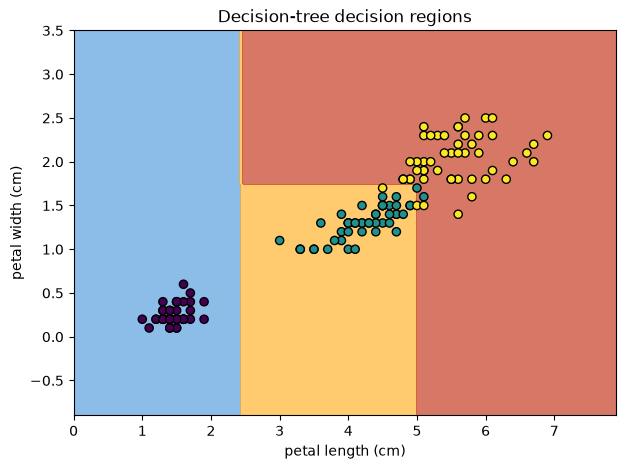

In [39]:
# 习题5（选做）：用两个特征画出决策边界
from sklearn.inspection import DecisionBoundaryDisplay

two_features = ["petal length (cm)", "petal width (cm)"]
X_two = X_iris[two_features]

boundary_tree = DecisionTreeClassifier(max_depth=3, random_state=3)
boundary_tree.fit(X_two, y_iris)

fig, ax = plt.subplots(figsize=(7, 5))
DecisionBoundaryDisplay.from_estimator(
    boundary_tree,
    X_two,
    response_method="predict",
    cmap="Pastel1",
    alpha=0.6,
    ax=ax,
)
scatter = ax.scatter(
    X_two.iloc[:, 0],
    X_two.iloc[:, 1],
    c=y_iris,
    cmap="viridis",
    edgecolor="black",
    s=35,
)
ax.set_title("Decision-tree decision regions")
ax.set_xlabel(two_features[0])
ax.set_ylabel(two_features[1])
plt.show()

# 思考：图中的边界为什么总与某一个坐标轴平行？
